# Aprendizado por Reforço: agente PPO jogando Atari Boxing

Treinamento de um agente com **PPO (Proximal Policy Optimization)**, usando a biblioteca [Stable-Baselines3](https://stable-baselines3.readthedocs.io/en/master/), para jogar **Boxing** do Atari 2600 ([documentação do ambiente](https://ale.farama.org/environments/boxing/)) a partir apenas dos pixels da tela.

![Evolução do agente](resultados/evolucao.gif)

**Roteiro do notebook**

1. O ambiente
2. Preparação
3. Método (pré-processamento e PPO)
4. Treinamento
5. Curva de aprendizado
6. Avaliação final
7. Vídeos
8. Conclusão

## 1. O ambiente: Boxing

O agente controla o **boxeador branco** e luta contra o **boxeador preto**, controlado pela CPU, num ringue visto de cima.

| | |
|---|---|
| **Observação** | imagem RGB 210×160×3 |
| **Ações** | `Discrete(18)`: NOOP, FIRE (soco), 8 direções e 8 direções + soco |
| **Recompensa** | **+1** por soco acertado e **−1** por soco levado (soco de perto vale 2) |
| **Fim do episódio** | fim dos **2 minutos** de luta, ou **nocaute** quando alguém chega a 100 pontos |

O **placar de uma luta** (soma das recompensas) é a diferença entre os pontos do agente e os da CPU. Vai de −100 a +100.

## 2. Preparação

No terminal, na pasta do projeto:

```
py -3.12 -m venv .venv
.venv\Scripts\python -m pip install -r requirements.txt
```

Depois, no VS Code ou no Jupyter, selecione o kernel **`.venv`**.

In [1]:
import sys, torch

print("Python:", sys.executable)
print("GPU disponível:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Python: C:\Users\202401005185\Documents\aprendizado-por-reforco\.venv\Scripts\python.exe
GPU disponível: True NVIDIA RTX 2000 Ada Generation


In [2]:
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

env = gym.make("ALE/Boxing-v5")
obs, info = env.reset()

print("Observação:", obs.shape)
print("Ações:", env.action_space)
print("Significado das ações:", env.unwrapped.get_action_meanings())

env.close()

Observação: (210, 160, 3)
Ações: Discrete(18)
Significado das ações: ['NOOP', 'FIRE', 'UP', 'RIGHT', 'LEFT', 'DOWN', 'UPRIGHT', 'UPLEFT', 'DOWNRIGHT', 'DOWNLEFT', 'UPFIRE', 'RIGHTFIRE', 'LEFTFIRE', 'DOWNFIRE', 'UPRIGHTFIRE', 'UPLEFTFIRE', 'DOWNRIGHTFIRE', 'DOWNLEFTFIRE']


## 3. Método

### Pré-processamento das observações

O ambiente é criado com `make_atari_env` + `VecFrameStack` (função `make_env` em [`train_boxing.py`](train_boxing.py)). Esses wrappers aplicam o pré-processamento padrão de Atari:

- **Escala de cinza e redimensionamento para 84×84**, para reduzir o custo da rede convolucional.
- **Repetição de cada ação por 4 frames** (frame skip). O agente decide 15 vezes por segundo, e não 60.
- **Empilhamento dos últimos 4 frames.** Uma imagem sozinha não mostra movimento. Com 4 frames, a rede percebe para onde o oponente está indo e se ele está no meio de um soco.
- **Até 30 ações NOOP aleatórias no início** de cada luta, para variar a situação inicial.
- **Recompensa limitada a {−1, 0, +1}** durante o treino. Para medir o placar, usamos o valor real registrado pelo `Monitor`.

> **Correção em relação ao template do Freeway.** O `ALE/...-v5` já repete cada ação por 4 frames por padrão, e o `AtariWrapper` do SB3 repete por mais 4. Juntos, o agente só agiria a cada **16** frames. Por isso o ambiente é criado com `frameskip=1`, deixando o frame skip só por conta do wrapper.

### Algoritmo: PPO

O PPO é um método **ator-crítico on-policy**. A cada iteração ele:

1. coleta experiência com a política atual em vários ambientes paralelos;
2. estima as vantagens com GAE;
3. atualiza a rede com uma função objetivo *recortada* (clipped), que impede a política nova de se afastar demais da anterior.

A política é uma `CnnPolicy`: a rede convolucional "Nature CNN" (3 camadas convolucionais + 1 densa), com duas saídas, uma para a política (ator) e outra para o valor (crítico).

| Hiperparâmetro | Valor | Função |
|---|---|---|
| `n_envs` | 8 | jogos rodando em paralelo (`SubprocVecEnv`) |
| `n_steps` | 128 | passos por ambiente em cada rollout (1024 no total) |
| `batch_size` | 256 | tamanho do minibatch |
| `n_epochs` | 4 | passadas de otimização sobre cada rollout |
| `learning_rate` | 2,5e-4 → 0 | taxa de aprendizado, com decaimento linear |
| `clip_range` | 0,1 → 0 | limite de mudança da política, com decaimento linear |
| `ent_coef` | 0,01 | bônus de entropia (exploração) |
| `vf_coef` | 0,5 | peso da perda do crítico |
| `gamma` / `gae_lambda` | 0,99 / 0,95 | desconto e GAE |
| `total_timesteps` | 10.000.000 | passos totais do agente (~40 milhões de frames do Atari) |

São os hiperparâmetros de PPO para Atari do [RL Baselines3 Zoo](https://github.com/DLR-RM/rl-baselines3-zoo).

## 4. Treinamento

O treino é feito pelo script [`train_boxing.py`](train_boxing.py), porque leva cerca de 1h35 numa GPU NVIDIA RTX 2000 Ada (~1.750 passos/s):

```
.venv\Scripts\python train_boxing.py
```

Durante o treino:

- a cada **250 mil passos**, o agente joga 5 lutas de avaliação, e o melhor modelo é salvo em `modelos/best_model.zip`;
- a cada **1 milhão de passos**, um checkpoint é salvo em `modelos/checkpoints/`;
- as métricas vão para `resultados/tensorboard/`.

Em paralelo, o script [`record_videos.py`](record_videos.py) observa os checkpoints e grava um vídeo de uma luta completa para cada um, em `resultados/videos/`.

O modelo treinado já está no repositório. Para treinar de novo, mude `TREINAR` para `True`.

In [3]:
import subprocess, sys

TREINAR = False

if TREINAR:
    subprocess.run([sys.executable, "train_boxing.py"], check=True)
else:
    print("Treino pulado. Usando o modelo já treinado em modelos/best_model.zip")

Treino pulado. Usando o modelo já treinado em modelos/best_model.zip


### Monitoramento com TensorBoard

Para ver todas as métricas do treino de forma interativa, rode a célula abaixo ou use `.venv\Scripts\tensorboard --logdir resultados/tensorboard` e acesse http://localhost:6006.

- `rollout/ep_rew_mean`: placar médio das últimas 100 lutas de treino
- `rollout/ep_len_mean`: duração média das lutas, em frames
- `eval/mean_reward`: placar médio das lutas de avaliação
- `train/*`: perdas do PPO, entropia, KL aproximado, fração de clipping

In [ ]:
import os, sys, shutil

# Aponta o %tensorboard para o executável do mesmo Python do kernel
base = os.path.dirname(sys.executable)
candidatos = [
    os.path.join(base, "tensorboard.exe"),             # venv no Windows
    os.path.join(base, "Scripts", "tensorboard.exe"),  # Python "global" no Windows
    os.path.join(base, "tensorboard"),                 # Linux/Mac/Colab
]
tb = next((c for c in candidatos if os.path.exists(c)), shutil.which("tensorboard"))
if tb:
    os.environ["TENSORBOARD_BINARY"] = tb

%load_ext tensorboard
%tensorboard --logdir ./resultados/tensorboard/

## 5. Curva de aprendizado

Gráficos gerados a partir dos logs do TensorBoard e do histórico de avaliações (`modelos/evaluations.npz`).

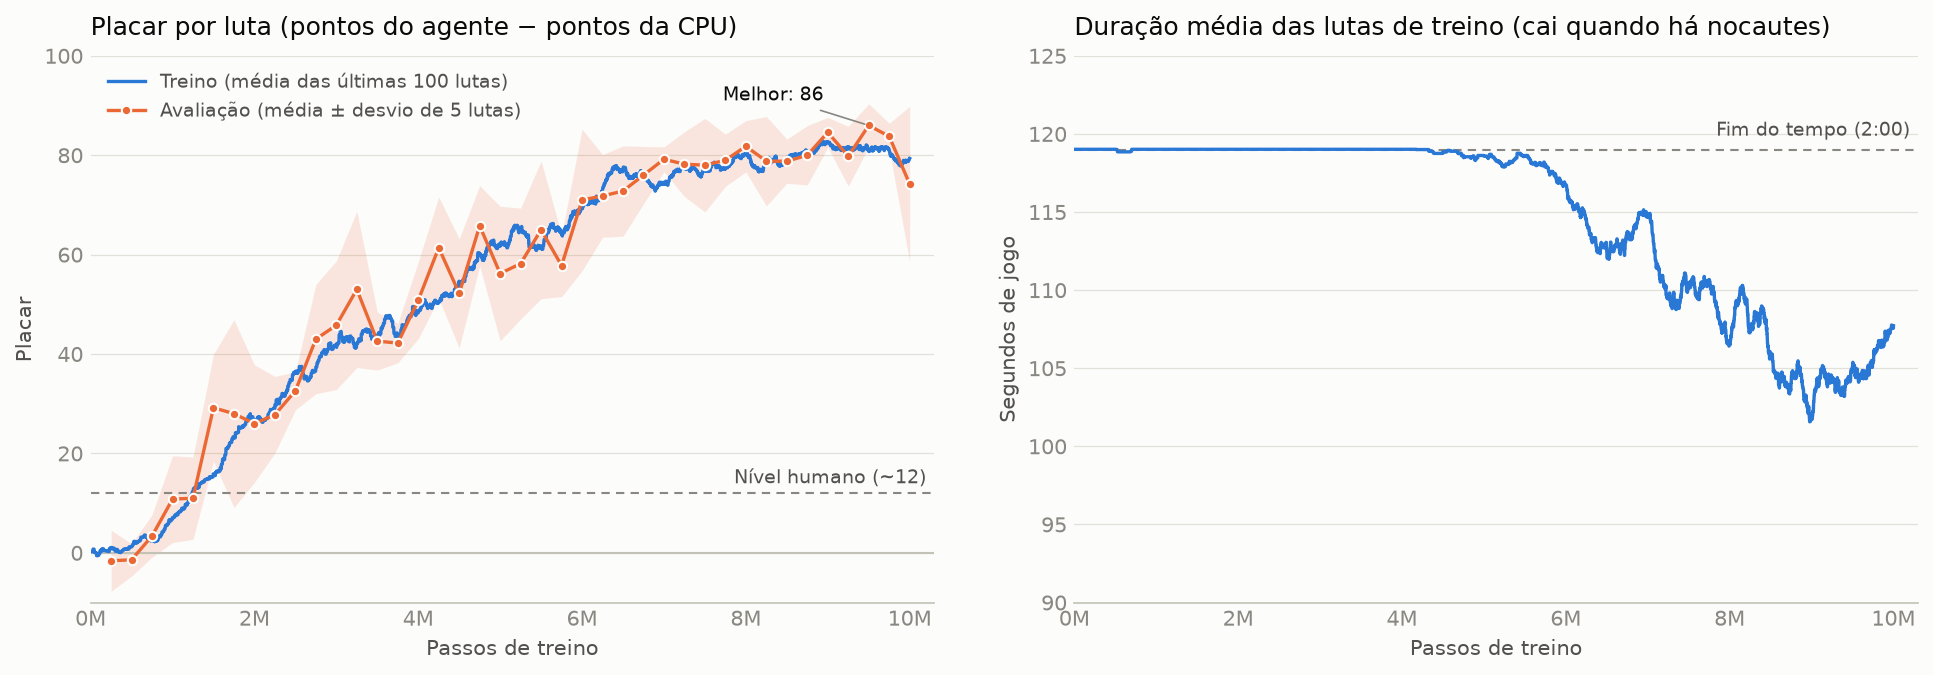

In [4]:
import glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

ea = EventAccumulator(sorted(glob.glob("resultados/tensorboard/PPO_boxing_*"))[-1])
ea.Reload()

def serie(tag):
    s = ea.Scalars(tag)
    return np.array([e.step for e in s]), np.array([e.value for e in s])

passos_tr, placar_tr = serie("rollout/ep_rew_mean")
passos_len, frames_tr = serie("rollout/ep_len_mean")

ev = np.load("modelos/evaluations.npz")
passos_ev = ev["timesteps"]
media_ev, dp_ev = ev["results"].mean(axis=1), ev["results"].std(axis=1)

# Estilo
AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA2, APAGADO = "#0b0b0b", "#52514e", "#898781"
GRADE, EIXO, FUNDO = "#e1e0d9", "#c3c2b7", "#fcfcfb"

def estilo(ax, titulo, ylabel):
    ax.set_facecolor(FUNDO)
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=12, pad=10)
    ax.set_ylabel(ylabel, color=TINTA2)
    ax.set_xlabel("Passos de treino", color=TINTA2)
    ax.grid(axis="y", color=GRADE, linewidth=0.6)
    ax.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(EIXO)
    ax.tick_params(colors=APAGADO, length=0)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:.0f}M"))
    ax.set_xlim(0, 10.3e6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), dpi=150, facecolor=FUNDO)

# (a) Placar
ax1.axhline(12, color=APAGADO, linewidth=1, linestyle=(0, (4, 3)))
ax1.text(10.2e6, 14, "Nível humano (~12)", color=TINTA2, fontsize=9, ha="right")
ax1.axhline(0, color=EIXO, linewidth=1)
ax1.plot(passos_tr, placar_tr, color=AZUL, linewidth=1.6, label="Treino (média das últimas 100 lutas)")
ax1.fill_between(passos_ev, media_ev - dp_ev, media_ev + dp_ev, color=LARANJA, alpha=0.15, linewidth=0)
ax1.plot(passos_ev, media_ev, color=LARANJA, linewidth=1.6, marker="o", markersize=4.5,
         markeredgecolor=FUNDO, markeredgewidth=1, label="Avaliação (média ± desvio de 5 lutas)")
i_best = media_ev.argmax()
ax1.annotate(f"Melhor: {media_ev[i_best]:.0f}", (passos_ev[i_best], media_ev[i_best]),
             xytext=(-70, 12), textcoords="offset points", color=TINTA, fontsize=9,
             arrowprops=dict(arrowstyle="-", color=APAGADO, linewidth=0.8))
ax1.set_ylim(-10, 100)
estilo(ax1, "Placar por luta (pontos do agente − pontos da CPU)", "Placar")
ax1.legend(loc="upper left", frameon=False, fontsize=9, labelcolor=TINTA2)

# (b) Duração das lutas
ax2.axhline(119, color=APAGADO, linewidth=1, linestyle=(0, (4, 3)))
ax2.text(10.2e6, 119.6, "Fim do tempo (2:00)", color=TINTA2, fontsize=9, va="bottom", ha="right")
ax2.plot(passos_len, frames_tr / 60, color=AZUL, linewidth=1.6)
ax2.set_ylim(90, 125)
estilo(ax2, "Duração média das lutas de treino (cai quando há nocautes)", "Segundos de jogo")

fig.tight_layout(w_pad=3)
fig.savefig("resultados/curva_aprendizado.png", facecolor=FUNDO, bbox_inches="tight")
plt.show()

## 6. Avaliação final

O melhor modelo luta **20 lutas novas**, com uma semente diferente das usadas no treino, e é comparado a um **agente aleatório** (linha de base sem treino). As ações são amostradas da política (`deterministic=False`). Uma luta que termina antes dos 2 minutos acabou em nocaute.

In [5]:
import json
import numpy as np
import pandas as pd
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.utils import set_random_seed
from train_boxing import make_env

N_LUTAS = 20
SEMENTE = 2026
FRAMES_LUTA_COMPLETA = 7100  # uma luta de 2 minutos tem ~7140 frames; menos que isso = nocaute


class AgenteAleatorio:
    # Mesma interface do PPO.predict, mas escolhendo ações ao acaso.
    def __init__(self, env):
        self.action_space = env.action_space

    def predict(self, obs, state=None, episode_start=None, deterministic=False):
        return np.array([self.action_space.sample() for _ in range(len(obs))]), None


def avaliar(criar_agente):
    set_random_seed(SEMENTE)
    env = make_env(n_envs=1, seed=SEMENTE)
    env.action_space.seed(SEMENTE)
    agente = criar_agente(env)
    placares, frames = evaluate_policy(agente, env, n_eval_episodes=N_LUTAS, deterministic=False,
                                       return_episode_rewards=True)
    env.close()
    placares, frames = np.array(placares), np.array(frames)
    ko = frames < FRAMES_LUTA_COMPLETA
    return {
        "placar_medio": float(placares.mean()),
        "desvio_padrao": float(placares.std()),
        "placar_min": float(placares.min()),
        "placar_max": float(placares.max()),
        "vitorias": int((placares > 0).sum()),
        "empates": int((placares == 0).sum()),
        "derrotas": int((placares < 0).sum()),
        "nocautes_aplicados": int((ko & (placares > 0)).sum()),
        "nocautes_sofridos": int((ko & (placares < 0)).sum()),
        "duracao_media_s": float(frames.mean() / 60),
        "placares": placares.tolist(),
    }


ev = np.load("modelos/evaluations.npz")
passos_best = int(ev["timesteps"][ev["results"].mean(axis=1).argmax()])

avaliacao = {
    "Agente aleatório": avaliar(AgenteAleatorio),
    f"PPO (melhor modelo, {passos_best / 1e6:.2f}M passos)": avaliar(
        lambda env: PPO.load("modelos/best_model", env=env, device="cpu")),
}

with open("resultados/avaliacao_final.json", "w", encoding="utf-8") as f:
    json.dump({"n_lutas": N_LUTAS, "semente": SEMENTE, "agentes": avaliacao}, f, ensure_ascii=False, indent=2)

tabela = pd.DataFrame({
    nome: {
        "Placar médio": f"{r['placar_medio']:+.1f} ± {r['desvio_padrao']:.1f}",
        "Pior / melhor luta": f"{r['placar_min']:+.0f} / {r['placar_max']:+.0f}",
        "Vitórias / empates / derrotas": f"{r['vitorias']} / {r['empates']} / {r['derrotas']}",
        "Nocautes aplicados": f"{r['nocautes_aplicados']} de {N_LUTAS}",
        "Nocautes sofridos": f"{r['nocautes_sofridos']} de {N_LUTAS}",
        "Duração média da luta": f"{r['duracao_media_s']:.0f} s",
    }
    for nome, r in avaliacao.items()
})
tabela

,Agente aleatório,"PPO (melhor modelo, 9.50M passos)"
Placar médio,+1.2 ± 5.8,+82.0 ± 10.4
Pior / melhor luta,-9 / +19,+46 / +93
Vitórias / empates / derrotas,10 / 3 / 7,20 / 0 / 0
Nocautes aplicados,0 de 20,19 de 20
Nocautes sofridos,0 de 20,0 de 20
Duração média da luta,119 s,106 s


### Placar de cada luta

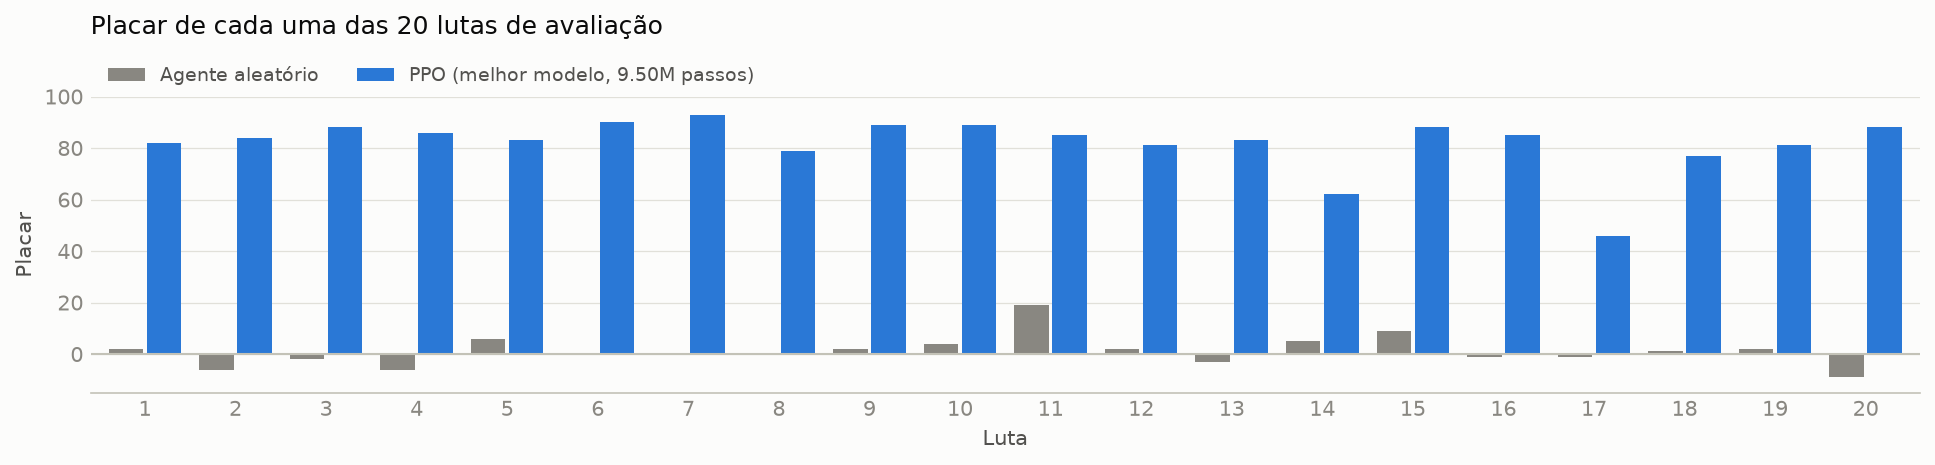

In [6]:
fig, ax = plt.subplots(figsize=(13, 3.2), dpi=150, facecolor=FUNDO)
lutas = np.arange(1, N_LUTAS + 1)
largura = 0.38
for i, (nome, r) in enumerate(avaliacao.items()):
    cor = APAGADO if i == 0 else AZUL
    ax.bar(lutas + (i - 0.5) * (largura + 0.04), r["placares"], width=largura, color=cor, label=nome)
ax.axhline(0, color=EIXO, linewidth=1)
ax.set_xticks(lutas)
estilo(ax, "Placar de cada uma das 20 lutas de avaliação", "Placar")
ax.set_title("Placar de cada uma das 20 lutas de avaliação", loc="left", color=TINTA, fontsize=12, pad=30)
ax.set_xlabel("Luta", color=TINTA2)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}"))
ax.set_xlim(0.4, N_LUTAS + 0.6)
ax.set_ylim(-15, 100)
ax.legend(loc="lower left", bbox_to_anchor=(0, 0.98), frameon=False, fontsize=9, labelcolor=TINTA2, ncol=2)
fig.tight_layout()
plt.show()

## 7. Vídeos

### Evolução durante o treino

Os quatro painéis mostram os primeiros 10 segundos de uma luta em diferentes etapas do treino, sempre com a mesma semente. O GIF é gerado a partir dos checkpoints locais. Se eles não existirem, a célula só mostra o GIF já salvo.

GIF salvo em resultados/evolucao.gif (0.6 MB)


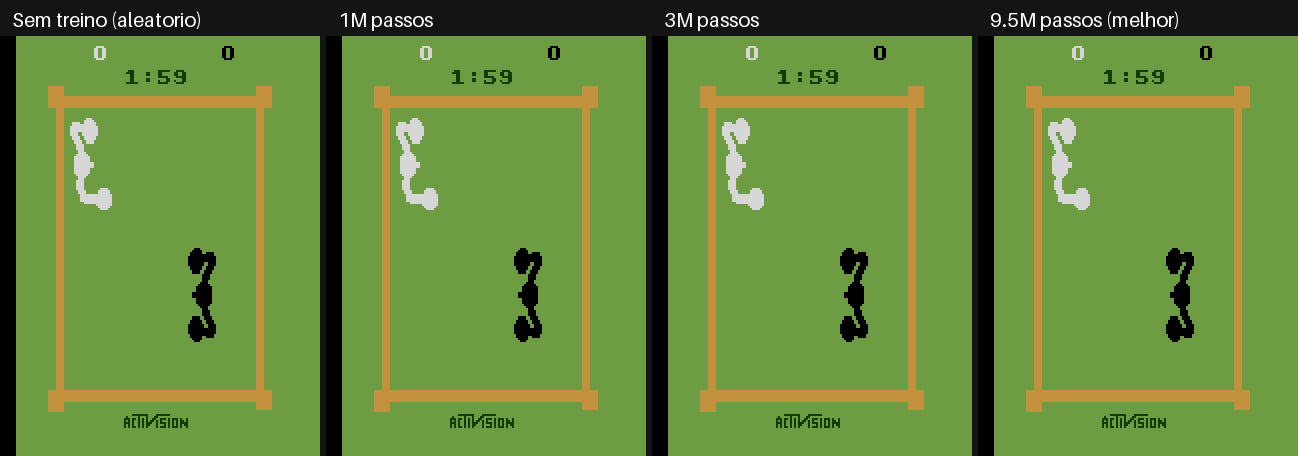

In [7]:
import os
import imageio
from PIL import Image as PILImage
from IPython.display import Image, display
from record_videos import play, add_label, get_font

GIF = "resultados/evolucao.gif"
ETAPAS = [
    (None, "Sem treino (aleatorio)"),
    ("modelos/checkpoints/boxing_ppo_1000000_steps.zip", "1M passos"),
    ("modelos/checkpoints/boxing_ppo_3000000_steps.zip", "3M passos"),
    ("modelos/best_model.zip", f"{passos_best / 1e6:.1f}M passos (melhor)"),
]

if all(p is None or os.path.exists(p) for p, _ in ETAPAS):
    N_PASSOS = 150  # 10 segundos de jogo
    fonte = get_font(20)
    paineis = []
    for caminho, rotulo in ETAPAS:
        frames, _ = play(caminho, max_steps=N_PASSOS)
        paineis.append([add_label(f, rotulo, fonte, scale=2, bar=36) for f in frames[:N_PASSOS]])
    n = min(len(p) for p in paineis)
    separador = np.full((paineis[0][0].shape[0], 6, 3), 20, dtype=np.uint8)
    quadros = []
    for t in range(n):
        partes = []
        for p in paineis:
            partes += [p[t], separador]
        quadros.append(PILImage.fromarray(np.hstack(partes[:-1])).quantize(colors=64))
    quadros[0].save(GIF, save_all=True, append_images=quadros[1:], duration=67, loop=0, optimize=True)
    print(f"GIF salvo em {GIF} ({os.path.getsize(GIF) / 1e6:.1f} MB)")

display(Image(filename=GIF))

### Luta completa do melhor modelo

Todos os vídeos estão em [`resultados/videos/`](resultados/videos). São lutas completas de 2 minutos, uma para cada milhão de passos de treino, além do agente aleatório, do melhor modelo e do modelo final.

In [8]:
from IPython.display import Video
Video("resultados/videos/melhor_modelo.mp4", embed=True, width=420)

## 8. Conclusão

O agente PPO aprendeu a jogar Boxing **só a partir dos pixels da tela**, sem nenhuma regra do jogo programada.

**Resultado final (20 lutas novas):** placar médio **+82,0 ± 10,4**, contra +1,2 ± 5,8 do agente aleatório. O agente **venceu as 20 lutas** e **nocauteou a CPU em 19**. Em média, ele chega aos 100 pontos com 1min46 de luta.

**Dinâmica do aprendizado:**
- **0 a 1M passos:** o agente sai do comportamento aleatório (placar ≈ 0).
- **~1,5M passos:** passa do nível de um jogador humano (~12 pontos) e chega a ~29 na avaliação.
- **1,5M a 7M passos:** melhora de forma contínua, de ~30 para ~80.
- **~4,5M passos em diante:** a duração das lutas começa a cair. O agente passa a **nocautear** a CPU antes do fim do tempo.
- **7M a 10M passos:** platô entre 80 e 86. Com `learning_rate` e `clip_range` caindo para 0, as atualizações ficam cada vez menores no fim do treino. O melhor modelo (86 na avaliação) é o de 9,5M passos.

**Comportamento aprendido (vídeos):** sem treino, o boxeador anda e soca a esmo. Treinado, ele **vai direto até o oponente, fica frente a frente e soca sem parar**, Ele também leva socos, mas bem menos: como a luta termina quando ele chega a 100 e o placar médio é +82, a CPU faz em média menos de 20 pontos.

**O que foi importante:**
- **Corrigir o frame skip duplicado do template.** Sem isso, o agente agiria só a cada 16 frames.
- **Empilhar 4 frames,** para o agente perceber o movimento.
- **Usar 8 ambientes em paralelo + GPU,** com ~1.750 passos/s. Os 10M passos levaram cerca de 1h35.

**Limitações e próximos passos:**
- As avaliações durante o treino usam só 5 lutas. O desvio é alto, e a queda do último ponto (74) é ruído, não piora real: o modelo final faz +77 em 20 lutas.
- Treinar mais tempo ou ajustar os hiperparâmetros poderia aproximar o placar de 100, nocauteando sem levar socos.
- Comparar com outros algoritmos (DQN, A2C) no mesmo ambiente.